## Final Project - Sophia Jensen INFO 2201-010

In this project, I aim to look at the relationship between how much MLB teams spend on player payroll and how well they perform during the regular season. I think a common belief among fans is that you can buy wins or that richer teams with higher payrolls will naturally dominate the standings (As a Dodger fan I hear this all the time!). However, we often see examples of big spending teams that dont make the playoffs and smaller market teams that outperform. This makes the true effect of spending on performance a non-obvious question that I am excited to learn more about!

I define team spending as each team’s total payroll (in dollars) and performance as regular season winning percentage (Win%). Using a historical MLB payroll dataset (CSV), I combine it with league standings from an HTML table and metropolitan population data from a Wikipedia page (HTML) to approximate market size. After cleaning and merging these sources by team and year, I analyze how strongly payroll predicts win percentage and whether there is evidence of diminishing returns for the highest spending teams.

### Research Question: To what extent does team payroll predict regular-season performance in MLB teams in 2023, and how effectively do the highest spending teams translate their payroll into wins?

Why this question is non-obvious:

Most people would expect the more money = more wins. However, some high spending teams underperform and some lower spending teams overperform. 
In this project I will use real data to quantify how strong the relationship actually is, and to see whether additional spending keeps helping or levels off.

## Data Sources

To answer this question, I combine three data sources with different structures:

1. MLB Historical Payroll (CSV) – A CSV file with team payroll by year, including 
   total payroll in dollars.  
2. MLB Standings (HTML table) – A saved HTML page with 2023 league standings 
   scraped from Baseball-Reference, including wins, losses, and win percentage.  
3. Metro Population (HTML) – A saved Wikipedia page with a table of 
   North American metropolitan areas and their populations, used as a rough estimate for each team’s market size.

### Loading payroll data (CSV)

In [1]:
import pandas as pd
payroll = pd.read_csv("MLB_HistoricalPayroll.csv")
payroll

,Year,Rank,Team,League,26ManPayroll,InjuredReserve,Retained,Buried,TotalPayroll,Win%,AVG,OBP,SLG,OPS,ERA,WHIP,Postseason
0,2023,21,Arizona Diamondbacks,NL,"$60,263,998","$11,197,775","$39,202,529","$8,593,349","$119,257,651",0.519,0.250,0.322,0.408,0.730,4.48,1.32,1
1,2023,10,Atlanta Braves,NL,"$158,186,507","$34,160,535","$11,447,888","$2,444,201","$206,239,131",0.642,0.276,0.344,0.501,0.845,4.14,1.30,1
2,2023,29,Baltimore Orioles,AL,"$53,159,734","$3,179,476","$9,861,733","$4,860,104","$71,061,047",0.623,0.255,0.321,0.421,0.742,3.89,1.24,1
3,2023,13,Boston Red Sox,AL,"$128,063,857","$28,736,341","$22,444,333","$3,682,265","$182,926,796",0.481,0.258,0.324,0.424,0.748,4.52,1.34,0
4,2023,11,Chicago Cubs,NL,"$134,251,105","$12,522,069","$35,403,285","$6,732,899","$188,909,358",0.512,0.254,0.330,0.421,0.751,4.08,1.28,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,2020,10,St. Louis Cardinals,NL,"$51,757,860","$12,343,763","$12,000,000","$1,087,757","$73,246,343",0.517,0.234,0.323,0.371,0.694,3.90,1.23,1
116,2020,28,Tampa Bay Rays,AL,"$21,769,463","$1,958,020","$2,086,951","$2,476,255","$28,290,689",0.667,0.238,0.328,0.425,0.753,3.56,1.22,1
117,2020,15,Texas Rangers,AL,"$30,877,925","$16,905,177","$15,338,320","$843,955","$64,214,137",0.367,0.217,0.285,0.364,0.648,5.02,1.38,0
118,2020,19,Toronto Blue Jays,AL,"$33,467,052","$5,114,444","$14,667,030","$1,538,164","$54,997,060",0.533,0.255,0.325,0.441,0.766,4.60,1.46,1


### Cleaning payroll data (CSV)

Here I wanted to filter the payroll data to the 2023 season and convert the total payroll 
column from a formatted string (with `$` and `,`) into a numeric value that I 
can use for analysis.

In [20]:
# Filtering to 2023 only and making a copy
payroll_2023 = payroll[payroll["Year"] == 2023].copy()

# Converting TotalPayroll from a string like to a numeric value
payroll_2023["TotalPayroll_num"] = (
    payroll_2023["TotalPayroll"]
    .str.replace("[$,]", "", regex=True)   # remove $ and commas
    .astype(float)
)

# Keeping only the columns I need for now
payroll_2023 = payroll_2023[["Team", "Year", "TotalPayroll", "TotalPayroll_num"]]

payroll_2023

,Team,Year,TotalPayroll,TotalPayroll_num
0,Arizona Diamondbacks,2023,"$119,257,651",119257651.0
1,Atlanta Braves,2023,"$206,239,131",206239131.0
2,Baltimore Orioles,2023,"$71,061,047",71061047.0
3,Boston Red Sox,2023,"$182,926,796",182926796.0
4,Chicago Cubs,2023,"$188,909,358",188909358.0
5,Chicago White Sox,2023,"$162,863,836",162863836.0
6,Cincinnati Reds,2023,"$96,577,288",96577288.0
7,Cleveland Guardians,2023,"$91,861,627",91861627.0
8,Colorado Rockies,2023,"$171,026,607",171026607.0
9,Detroit Tigers,2023,"$121,494,514",121494514.0


### Loading Standings data (HTML)

In [21]:
from bs4 import BeautifulSoup
with open("standings_2023.html") as html_file:
    soup = BeautifulSoup(html_file.read(), "html.parser")

tables = soup.find_all("table")

header = None       # holds the header row 
all_rows = []       # holds data rows from all relevant tables

for t in tables:
    # get all non empty rows from this table
    rows = [
        [c.get_text(strip=True) for c in row.find_all(["th", "td"])]
        for row in t.find_all("tr")
        if row.find_all(["th", "td"])
    ]
    if not rows:
        continue # used to end the current iteration in the for loop and continue to the next iteration

    # first row = header for this table rest = data
    h = rows[0]
    data_rows = rows[1:]

    # only keep tables that look like standings tables
    if {"Tm", "W", "L", "W-L%"}.issubset(h):
        if header is None:
            header = h       # remember the header once
        all_rows.extend(data_rows)  # add these teams to the big list

# build one df from all the rows
standings_2023 = pd.DataFrame(all_rows, columns=header)
standings_2023

,Tm,W,L,W-L%,GB
0,Baltimore Orioles,101,61,.623,--
1,Tampa Bay Rays,99,63,.611,2.0
2,Toronto Blue Jays,89,73,.549,12.0
3,New York Yankees,82,80,.506,19.0
4,Boston Red Sox,78,84,.481,23.0
5,Minnesota Twins,87,75,.537,--
6,Detroit Tigers,78,84,.481,9.0
7,Cleveland Guardians,76,86,.469,11.0
8,Chicago White Sox,61,101,.377,26.0
9,Kansas City Royals,56,106,.346,31.0


### Cleaning standings data (HTML)

Here I convert the wins, losses, and win percentage columns to numeric types and 
keep only the rows that correspond to actual MLB teams. I also rename columns so 
they match the payroll data.

In [22]:
# starting from the scraped table
standings_2023_clean = standings_2023.copy()

# Convert W, L, and W-L% to numeric and make  bad values become NaN
standings_2023_clean["W"] = pd.to_numeric(standings_2023_clean["W"], errors="coerce")  # errors = "coerce" means if something isn’t a valid number turn it into NaN instead of crashing
standings_2023_clean["L"] = pd.to_numeric(standings_2023_clean["L"], errors="coerce")
standings_2023_clean["W-L%"] = pd.to_numeric(standings_2023_clean["W-L%"], errors="coerce")

# Drop any rows that aren't real team rows 
standings_2023_clean = standings_2023_clean.dropna(subset=["W", "L", "W-L%"]).copy()

# W and L back to int and Win% to float
standings_2023_clean["W"] = standings_2023_clean["W"].astype(int)
standings_2023_clean["L"] = standings_2023_clean["L"].astype(int)
standings_2023_clean["W-L%"] = standings_2023_clean["W-L%"].astype(float)

# Rename the colums so that they match better with my project
standings_2023_clean = standings_2023_clean.rename(columns={
    "Tm": "Team",
    "W-L%": "WinPct"
})

# Keeping only colums I want 
standings_2023_clean = standings_2023_clean[["Team", "W", "L", "WinPct"]]

standings_2023_clean

,Team,W,L,WinPct
0,Baltimore Orioles,101,61,0.623
1,Tampa Bay Rays,99,63,0.611
2,Toronto Blue Jays,89,73,0.549
3,New York Yankees,82,80,0.506
4,Boston Red Sox,78,84,0.481
5,Minnesota Twins,87,75,0.537
6,Detroit Tigers,78,84,0.481
7,Cleveland Guardians,76,86,0.469
8,Chicago White Sox,61,101,0.377
9,Kansas City Royals,56,106,0.346


### Loading metro population data (HTML)

In [23]:
# open the Wikipedia HTML
with open("List of North American metropolitan areas by population - Wikipedia.html") as html_file:
    html_doc = html_file.read()

soup = BeautifulSoup(html_doc, "html.parser")

tables = soup.find_all("table")
print("Number of tables:", len(tables))


table = tables[0]

rows = []
for row in table.find_all("tr"):
    cells = [c.get_text(strip=True) for c in row.find_all(["th", "td"])]
    if len(cells) == 0:
        continue
    rows.append(cells)

header = rows[0]
data_rows = rows[1:]

metro_df = pd.DataFrame(data_rows, columns=header)

# clean up column names and population
metro_df = metro_df.rename(columns={
    "Metropolitanarea": "Market",
    "Population": "Population"
})

metro_df["Population"] = (
    metro_df["Population"]
    .str.replace(",", "", regex=False)
    .astype(int)
)

# keep only the columns we need
metro_df = metro_df[["Market", "Population"]]

metro_df

Number of tables: 2


,Market,Population
0,Mexico City,22752682
1,New York,21201083
2,Los Angeles,12678000
3,Chicago,9408576
4,Dallas–Fort Worth,8344032
5,Houston,7796182
6,Toronto,7106379
7,Miami,6457988
8,Atlanta,6411149
9,"Washington, D.C.",6160891


## Data Integration: Combining payroll, performance, and market size

With cleaned payroll, standings, and metro population data, I now merge these 
sources into a single team-level DataFrame for the 2023 season.

In [24]:
# mapping from MLB team name to the metro market name in metro_df
team_to_market = {
    "Atlanta Braves": "Atlanta",
    "Arizona Diamondbacks": "Arizona",
    "Baltimore Orioles": "Baltimore",
    "Boston Red Sox": "Boston",
    "Chicago Cubs": "Chicago",
    "Chicago White Sox": "Chicago",
    "Cincinnati Reds": "Cincinnati",
    "Cleveland Guardians": "Cleveland",
    "Colorado Rockies": "Denver",
    "Detroit Tigers": "Detroit",
    "Houston Astros": "Houston",
    "Kansas City Royals": "Kansas City",
    "Los Angeles Angels": "Los Angeles",
    "Los Angeles Dodgers": "Los Angeles",
    "Miami Marlins": "Miami",
    "Milwaukee Brewers": "Milwaukee",
    "Minnesota Twins": "Minneapolis–Saint Paul",
    "New York Mets": "New York City",
    "New York Yankees": "New York City",
    "Oakland Athletics": "San Francisco Bay Area",
    "Philadelphia Phillies": "Philadelphia",
    "Pittsburgh Pirates": "Pittsburgh",
    "San Diego Padres": "San Diego",
    "San Francisco Giants": "San Francisco Bay Area",
    "Seattle Mariners": "Seattle",
    "St. Louis Cardinals": "St. Louis",
    "Tampa Bay Rays": "Tampa Bay",
    "Texas Rangers": "Dallas–Fort Worth",
    "Toronto Blue Jays": "Toronto",
    "Washington Nationals": "Washington, D.C."
}

# using pd.Merge to merge payroll and standings on Team
team_2023 = pd.merge(
    payroll_2023,
    standings_2023_clean,
    on="Team",
    how="inner"
)

# Then adding in Market using the mapping
team_2023["Market"] = team_2023["Team"].map(team_to_market)

# Merge in metro population
team_2023 = team_2023.merge(
    metro_df,
    on="Market",
    how="left"
)

team_2023

,Team,Year,TotalPayroll,TotalPayroll_num,W,L,WinPct,Market,Population
0,Arizona Diamondbacks,2023,"$119,257,651",119257651.0,84,78,0.519,Arizona,NaN
1,Atlanta Braves,2023,"$206,239,131",206239131.0,104,58,0.642,Atlanta,6411149.0
2,Baltimore Orioles,2023,"$71,061,047",71061047.0,101,61,0.623,Baltimore,2859024.0
3,Boston Red Sox,2023,"$182,926,796",182926796.0,78,84,0.481,Boston,5025517.0
4,Chicago Cubs,2023,"$188,909,358",188909358.0,83,79,0.512,Chicago,9408576.0
5,Chicago White Sox,2023,"$162,863,836",162863836.0,61,101,0.377,Chicago,9408576.0
6,Cincinnati Reds,2023,"$96,577,288",96577288.0,82,80,0.506,Cincinnati,2302815.0
7,Cleveland Guardians,2023,"$91,861,627",91861627.0,76,86,0.469,Cleveland,2171877.0
8,Colorado Rockies,2023,"$171,026,607",171026607.0,59,103,0.364,Denver,3052498.0
9,Detroit Tigers,2023,"$121,494,514",121494514.0,78,84,0.481,Detroit,NaN


### Combining data sources using dictionary mapping

Correlation between payroll and Win% (2023): 0.200


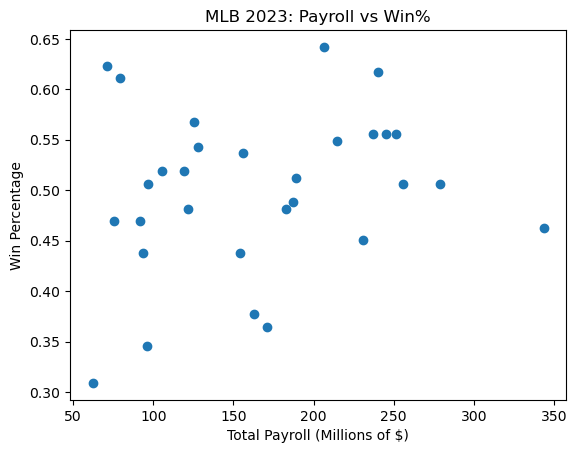

In [25]:
import matplotlib.pyplot as plt

# Make a payroll in millions column
team_2023["Payroll_Millions"] = team_2023["TotalPayroll_num"] / 1_000_000

# Correlation between payroll and Win%
corr = team_2023["Payroll_Millions"].corr(team_2023["WinPct"]) #using pandas’.corr() method to calculate the correlation coefficient. This gives a single number that summarizes how strongly payroll and win percentage move together
print(f"Correlation between payroll and Win% (2023): {corr:.3f}") #prints that value rounded to three decimal places

# Make my Scatter plot
plt.scatter(team_2023["Payroll_Millions"], team_2023["WinPct"])
plt.xlabel("Total Payroll (Millions of $)")
plt.ylabel("Win Percentage")
plt.title("MLB 2023: Payroll vs Win%")
plt.show()


This scatter plot shows the relationship between each MLB team’s total payroll in 2023 (x-axis) and its regular season win percentage (y-axis). Each point is equal to one team. We can see there is a slight upward trend meaning that higher payroll teams tend to have somewhat higher win percentages, however the points are widely scattered. The correlation between payroll and win percentage in 2023 is about 0.20, which I know from my statistics class that indicates a weak positive relationship. So, spending more is associated with winning a bit more, but payroll alone does not strongly predict performance. Teams with similar payrolls can finish with very different records and some lower payroll teams perform as well as or better than more
expensive teams. For my research question, this suggests that money helps to a limited extent but you can't fully buy wins. 

### Comparing low, medium, and high payroll teams

To look at if extra spending keeps paying off I decided to group teams into three tiers based on total payroll (low, medium, and high) and compare their average win percentage.

In [26]:

# The cut points for low / medium / high are about 1/3 and 2/3 
low_cut  = team_2023["TotalPayroll_num"].quantile(1/3)
high_cut = team_2023["TotalPayroll_num"].quantile(2/3)

# Function to turn a payroll value into a tier label
def payroll_to_tier(p):
    if p <= low_cut:
        return "Low payroll"
    elif p <= high_cut:
        return "Medium payroll"
    else:
        return "High payroll"

# Apply that function to make a new column
team_2023["PayrollTier"] = team_2023["TotalPayroll_num"].apply(payroll_to_tier)

# Summarize win percentage by tier
tier_summary = team_2023.groupby("PayrollTier")["WinPct"].agg(
    ["count", "mean", "min", "max"]
)
tier_summary

,count,mean,min,max
PayrollTier,,,,
High payroll,10,0.5402,0.451,0.642
Low payroll,10,0.4809,0.309,0.623
Medium payroll,10,0.4789,0.364,0.568


This table summarizes win percentage for three payroll tiers (low, medium, high). On average, high payroll teams win more (mean Win% ≈ 0.54) than low  and medium payroll teams (both around 0.48), this supports the idea that extra spending does help performance. However, the minimum and maximum values show overlap between tiers, meaning some lower payroll teams do as well as or better than highe payroll teams. This fits my hypothesis that money helps, but it does not fully buy wins.

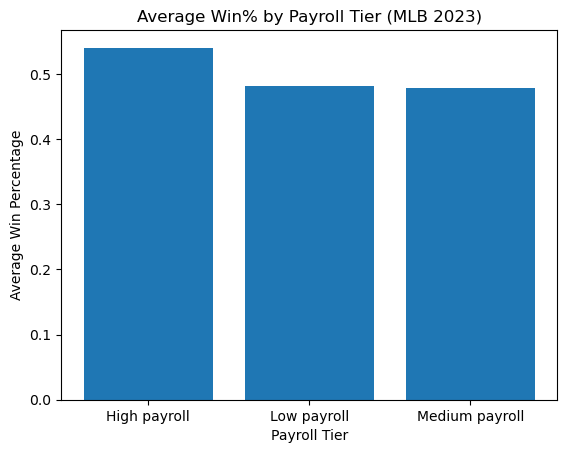

In [27]:
# Bar chart of average Win% by tier
avg_win_by_tier = team_2023.groupby("PayrollTier")["WinPct"].mean()

plt.bar(avg_win_by_tier.index.astype(str), avg_win_by_tier.values)
plt.xlabel("Payroll Tier")
plt.ylabel("Average Win Percentage")
plt.title("Average Win% by Payroll Tier (MLB 2023)")
plt.show()

This chart groups MLB teams into three payroll tiers (low, medium, and high)
based on 2023 total payroll and compares their average win percentage.

From the summary table above:

- Low payroll teams (bottom third) have an average win percentage of about 0.48
  (min ≈ 0.31, max ≈ 0.62).
- Medium payroll teams(middle third) have a similar average win percentage,
  around 0.48 (min ≈ 0.36, max ≈ 0.57).
- High payroll teams (top third) have a higher average win percentage of about
  0.54 (min ≈ 0.45, max ≈ 0.64).

This suggests that higher-spending teams do better on average, which is consistent with the weak positive correlation in the earlier scatter plot. However, the differences are not huge, and the min/max values show a lot of overlap: some low- and medium-payroll teams perform as well as or better than some of the most expensive teams. This supports the idea that payroll helps, but it does not fully determine performance and there may be diminishing returns at the top end.

## Market size, spending, and performance

In addition to just payroll, I was also able to collect metropolitan population for each state to act as a rough estimate for each team’s market size. Here I wanted to check if larger markets tend to spend more on payroll and whether they tend to win more games.

Correlation between population and payroll (millions): 0.7104858403561838
Correlation between population and Win%: 0.2543195829222336


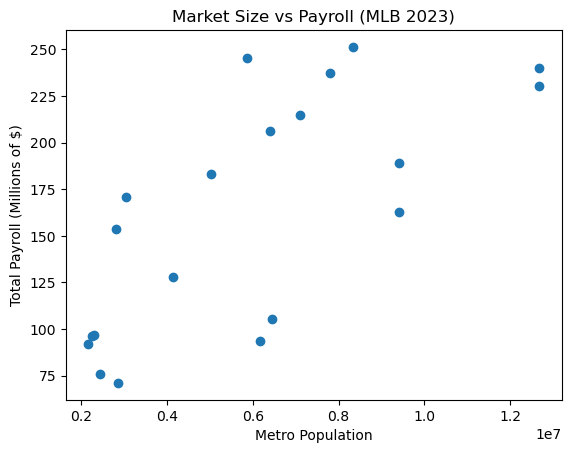

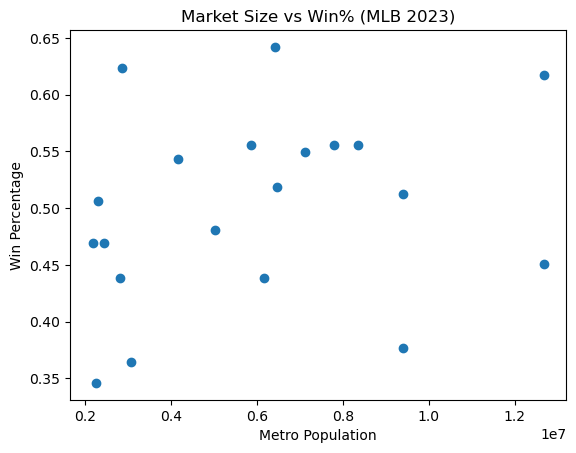

In [28]:
import matplotlib.pyplot as plt

#same thing as above to make it into millions 
team_2023["Payroll_Millions"] = team_2023["TotalPayroll_num"] / 1_000_000

# .corr again too to find the correlation coefficient. Gives a single number that shows how strong the realtionship is 
corr_pop_payroll = team_2023[["Population", "Payroll_Millions"]].corr().loc["Population", "Payroll_Millions"]
corr_pop_winpct = team_2023[["Population", "WinPct"]].corr().loc["Population", "WinPct"]

print("Correlation between population and payroll (millions):", corr_pop_payroll)
print("Correlation between population and Win%:", corr_pop_winpct)

# scatter plot for population vs payroll
plt.scatter(team_2023["Population"], team_2023["Payroll_Millions"])
plt.xlabel("Metro Population")
plt.ylabel("Total Payroll (Millions of $)")
plt.title("Market Size vs Payroll (MLB 2023)")
plt.show()

# scatter for population vs win% 
plt.scatter(team_2023["Population"], team_2023["WinPct"])
plt.xlabel("Metro Population")
plt.ylabel("Win Percentage")
plt.title("Market Size vs Win% (MLB 2023)")
plt.show()

The first scatter plot and correlation value show how metro population relates to team payroll. The correlation between population and payroll is about 0.71, which is a strong positive relationship. This means that teams in larger markets tend to spend significantly more on player payroll than teams in smaller markets. The second scatter plot and correlation value describe how population relates to win percentage. The correlation is only about 0.25, which is a pretty weak positive relationship. Larger markets win slightly more on average, but market size by itself does not strongly determine on the feild performance. Taking this as well as earlier results into account supports the idea that money and market size help, but they do not completely buy wins.

## Discussion and Limitations

Across my visualizations analyses, I find that money and market size matter, but they do not fully determine MLB team success. First, the overall correlation between total payroll and win percentage in 2023 is about 0.20, which is a weak positive relationship. Higher payroll teams tend to win a bit more, but there is a lot of scatter. Teams with similar payrolls can end up with very different records, and some lower payroll teams match or outperform more expensive teams. Second, when I group teams into low, medium, and high payroll tiers, the high payroll group has a noticeably higher average win percentage (about 0.54 compared to about 0.48 for the low and medium payroll groups). This suggests that extra spending is associated with better performance on average, but the min/max values for each tier show a lot of overlap, which again points to spending more helps but it does not guarantee wins. Third, market size is strongly related to spending but only weakly related to winning. Metro population and payroll have a correlation of about 0.71, meaning big markets usually spend more. However, the correlation between population and win percentage is only about 0.25, which shows that large markets do not automatically translate their financial advantages into wins.

When doing this project I wanted to take several limiatations into account:

- I am only focusing on a single season (2023), so my results might not generalize to other years with different injuries, rule changes, or economic conditions.
- Metro population is only a rough estimate for a team’s market size and does not nessicarily measure all revenue, TV deals, or ownership wealth.
- I use regular season win percentage and do not look at playoff performance or more advanced statistics like run differential.
- All the relationships in this project are correlational therefore, I can't claim that higher spending cause better performance only that they are associated.

Despite these limitations, the project demonstrates how combining multiple data sources (CSV and HTML tables) with Python can provide a clear picture of a common sports narrative.

## Conclusion

My research question asked: To what extent does team payroll predict regular-season performance in MLB teams in 2023, and how effectively do the highest spending teams translate their payroll into wins?

Using data from the 2023 season, I find that payroll has a real but limited connection to success. Payroll and win percentage are weakly correlated, and high payroll teams do better on average than low and medium payroll teams, but the differences are small and there is large overlap between groups. Market size strongly predicts how much teams spend, yet it only weakly predicts how much they win. Overall, the data suggest that money helps teams buy some extra wins, especially at the very top of the payroll distribution, but it does not guarantee success. There are so many other aspects of the game like coaching, player development, injuries that play important roles, which is why some wealthy teams underperform and some underdog teams overperform.

Sources:
Used a few sources to remind how to incorparte some stuff in my code 
- https://www.w3schools.com/python/ref_list_extend.asp
- https://www.w3schools.com/python/ref_keyword_continue.asp
- https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.merge.html
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.quantile.html